# Chapter 6 — Boltzmann machines

A Boltzmann machine (Section 6.3) is a stochastic Hopfield net with binary units $y_j\in\{0,1\}$. Unit $j$ is switched on with probability

$$P(y_j=1) = \frac{1}{1+e^{-\beta u_j}},\qquad u_j=\sum_i w_{ij}y_i,\qquad \beta = 1/T \quad\text{(Eq 6.1, 6.2)}$$

where $T$ is a *temperature*. At thermal equilibrium the network visits state $\mathbf y$ with the Boltzmann probability

$$p(\mathbf y)=\frac{1}{Z}e^{-\beta E(\mathbf y)},\qquad E(\mathbf y) = -\sum_{i<j}w_{ij}y_iy_j,\qquad Z=\sum_{k=1}^{2^K}e^{-\beta E(\mathbf y_k)}\quad\text{(Eq 6.3–6.5)}.$$

Biases are implemented, as in Section 5.2, by an extra unit whose state is clamped at $-1$.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scripts.boltzmann import (BoltzmannMachine, all_binary_states, geometric_schedule,
                               ising_to_binary, quadratic_energy, simulated_annealing)

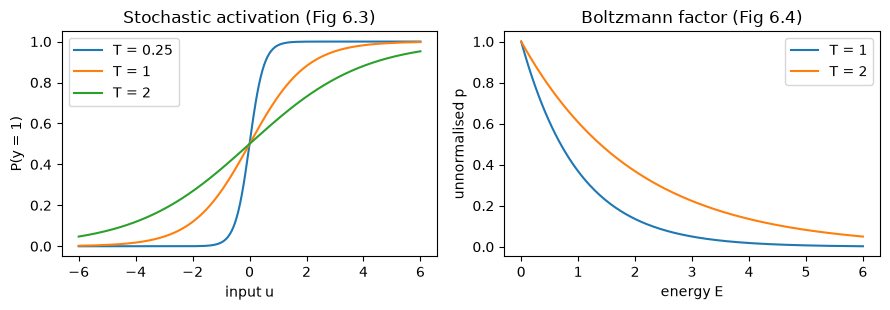

In [2]:
u = np.linspace(-6, 6, 200); E = np.linspace(0, 6, 200)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for T in [0.25, 1, 2]:
    axes[0].plot(u, 1 / (1 + np.exp(-u / T)), label=f"T = {T}")
for T in [1, 2]:
    axes[1].plot(E, np.exp(-E / T), label=f"T = {T}")
axes[0].set(xlabel="input u", ylabel="P(y = 1)", title="Stochastic activation (Fig 6.3)")
axes[1].set(xlabel="energy E", ylabel="unnormalised p", title="Boltzmann factor (Fig 6.4)")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## Simulated annealing (Section 6.4)

To find low-energy states we start hot (noisy decisions that can climb out of local minima) and cool slowly. At each temperature every unclamped unit is updated $S$ times by Eq 6.1, in random order without replacement (pseudocode, book page 77).

We test this on a 16-unit *spin glass*: random couplings $J_{ij}=\pm1$ between $\pm1$ spins, rewritten for 0/1 units ($W=4J$, $b_i=-2\sum_j J_{ij}$). Such energies have many local minima. Since $2^{16}=65536$, we can find the true global minimum by enumeration. "Greedy" descent is the same procedure at a fixed, near-zero temperature.

global minimum energy = -30  (attained by 2 states)


annealing reached the global minimum in 98% of runs
greedy descent reached it in            54% of runs


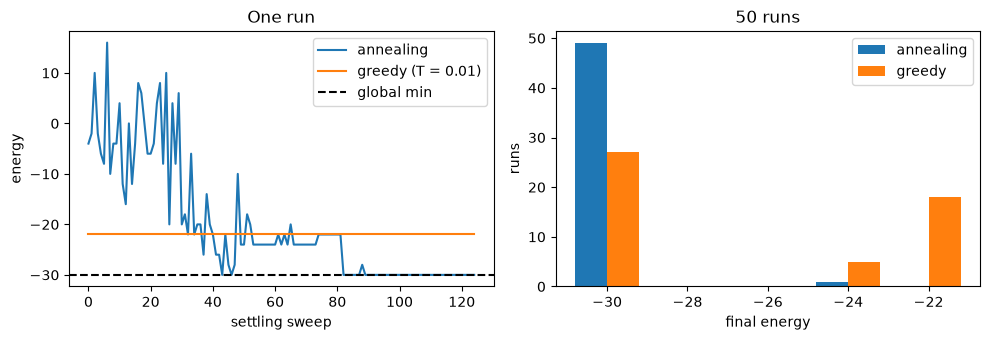

In [3]:
K = 16
rng = np.random.default_rng(6)
W, b = ising_to_binary(rng.choice([-1.0, 1.0], (K, K)))
S = all_binary_states(K)
E_all = -np.einsum("ni,ij,nj->n", S, np.triu(W, 1), S) - S @ b
e_min = E_all.min()
print(f"global minimum energy = {e_min:.0f}  (attained by {np.sum(E_all == e_min)} states)")

schedule = geometric_schedule(10.0, 0.2, 25)
n_settle = 5
n_runs = 50
final_anneal, final_greedy = [], []
for r in range(n_runs):
    y, trace_a = simulated_annealing(W, rng.integers(0, 2, K), schedule, n_settle, rng, b=b)
    final_anneal.append(quadratic_energy(W, y, b))
    y, trace_g = simulated_annealing(W, rng.integers(0, 2, K), [0.01], len(schedule) * n_settle, rng, b=b)
    final_greedy.append(quadratic_energy(W, y, b))
final_anneal, final_greedy = np.array(final_anneal), np.array(final_greedy)
print(f"annealing reached the global minimum in {np.mean(final_anneal == e_min):.0%} of runs")
print(f"greedy descent reached it in            {np.mean(final_greedy == e_min):.0%} of runs")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(trace_a, label="annealing"); axes[0].plot(trace_g, label="greedy (T = 0.01)")
axes[0].axhline(e_min, color="k", ls="--", label="global min")
axes[0].set(xlabel="settling sweep", ylabel="energy", title="One run"); axes[0].legend()
bins = np.arange(e_min - 1, max(final_anneal.max(), final_greedy.max()) + 3, 2)
axes[1].hist([final_anneal, final_greedy], bins=bins, label=["annealing", "greedy"])
axes[1].set(xlabel="final energy", ylabel="runs", title=f"{n_runs} runs"); axes[1].legend()
plt.tight_layout(); plt.show()

## Learning: wake and sleep (Sections 6.5–6.7)

Units are split into visible $\mathbf v$ and hidden $\mathbf h$. Learning makes the free-running ("sleep") visible distribution $p_s(\mathbf v)$ match the data ("wake") distribution $p_w(\mathbf v)$ by minimising the KL divergence

$$G=\sum_{\mathbf v}p_w(\mathbf v)\log\frac{p_w(\mathbf v)}{p_s(\mathbf v)}\quad\text{(Eq 6.7)},$$

equivalently maximising the log likelihood $L(\mathbf w)=\sum_t\log p_s(\mathbf v_t)$ (Eq 6.21). Differentiating gives the famous local learning rule (pseudocode, book page 82)

$$\Delta w_{ij} = \epsilon\beta\big(\langle y_iy_j\rangle_{\text{wake}}-\langle y_iy_j\rangle_{\text{sleep}}\big),$$

where *wake* statistics are measured with the visible units clamped to training vectors and *sleep* statistics with all units free. Averaging over the training set, $\beta(\langle\cdot\rangle_{\text{wake}}-\langle\cdot\rangle_{\text{sleep}}) = \partial (L/T)/\partial w_{ij} = -\partial G/\partial w_{ij}$.

For tiny networks we can compute both expectations **exactly** by enumerating all $2^K$ states; in general they are **estimated by simulated annealing** followed by sampling at equilibrium. First, check that the sampled gradient approaches the exact one as we collect more samples.

In [4]:
data = np.array([[1, 1, 0, 0], [0, 1, 1, 0], [0, 0, 1, 1], [1, 0, 0, 1]], dtype=float)
probe = BoltzmannMachine(4, 2, weight_scale=1.0, seed=0)
g_exact = probe.exact_gradient(data)
upper = np.triu(np.ones_like(g_exact, dtype=bool), 1)
for n in [5, 20, 100, 400]:
    wake, sleep = probe.sampled_stats(data, n_samples=n, n_chains=10)
    g = probe.beta * (wake - sleep)
    cos = g[upper] @ g_exact[upper] / np.linalg.norm(g[upper]) / np.linalg.norm(g_exact[upper])
    print(f"n_samples = {n:4d}: cosine(sampled, exact gradient) = {cos:.3f}")

n_samples =    5: cosine(sampled, exact gradient) = 0.836
n_samples =   20: cosine(sampled, exact gradient) = 0.952
n_samples =  100: cosine(sampled, exact gradient) = 0.988
n_samples =  400: cosine(sampled, exact gradient) = 0.999


## Training on a toy distribution

The data are the four 4-bit "ring" patterns `1100, 0110, 0011, 1001` (two adjacent bits on, with wrap-around), each with probability 1/4. We train a machine with 4 visible and 2 hidden units, once with exact statistics and once with annealing-based sampled statistics, and track the exact KL divergence $G$.

final KL: exact 0.032, sampled 0.074


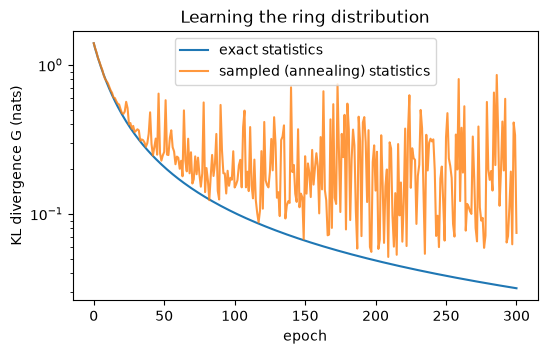

In [5]:
bm_exact = BoltzmannMachine(4, 2, seed=0).fit(data, n_epochs=300, lr=1.0, method="exact")
bm_sample = BoltzmannMachine(4, 2, seed=0).fit(data, n_epochs=300, lr=1.0, method="sample",
                                               n_samples=10, n_chains=8)
print(f"final KL: exact {bm_exact.kl_history[-1]:.3f}, sampled {bm_sample.kl_history[-1]:.3f}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(bm_exact.kl_history, label="exact statistics")
ax.plot(bm_sample.kl_history, label="sampled (annealing) statistics", alpha=0.8)
ax.set(xlabel="epoch", ylabel="KL divergence G (nats)", title="Learning the ring distribution")
ax.set_yscale("log"); ax.legend(); plt.show()

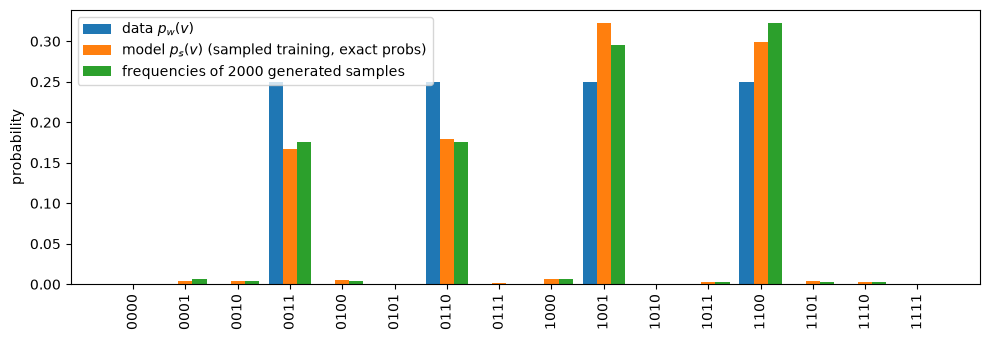

In [6]:
labels = ["".join(str(int(b)) for b in s) for s in all_binary_states(4)]
p_w = bm_exact.data_distribution(data)
samples = bm_sample.sample_visible(2000)
p_gen = bm_sample.data_distribution(samples)
x = np.arange(16); w = 0.27
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(x - w, p_w, w, label="data $p_w(v)$")
ax.bar(x, bm_sample.visible_probs(), w, label="model $p_s(v)$ (sampled training, exact probs)")
ax.bar(x + w, p_gen, w, label="frequencies of 2000 generated samples")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=90); ax.set_ylabel("probability")
ax.legend(); plt.tight_layout(); plt.show()

## Why hidden units matter: 3-bit parity

The even-parity patterns `000, 011, 101, 110` have every single-unit and pairwise statistic identical to the uniform distribution, so a machine with only visible units (which only models pairwise correlations) cannot do better than $G=\log 2$. Hidden units let the machine represent this higher-order structure.

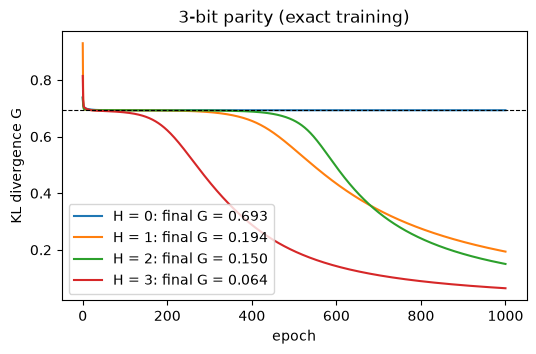

In [7]:
parity = np.array([[0, 0, 0], [0, 1, 1], [1, 0, 1], [1, 1, 0]], dtype=float)
fig, ax = plt.subplots(figsize=(6, 3.5))
for H in [0, 1, 2, 3]:
    m = BoltzmannMachine(3, H, weight_scale=0.5, seed=0).fit(parity, n_epochs=1000, lr=1.0)
    ax.plot(m.kl_history, label=f"H = {H}: final G = {m.kl_history[-1]:.3f}")
ax.axhline(np.log(2), color="k", ls="--", lw=0.8)
ax.set(xlabel="epoch", ylabel="KL divergence G", title="3-bit parity (exact training)")
ax.legend(); plt.show()